In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Cleaning and EDA



Objective: Create a clean dataset containing valid collision records that we can use for spatial analysis.

In [3]:
df = pd.read_csv("../data/raw/manhattan_collisions.csv")

In [4]:
df.head()

,collision_id,crash_date,crash_time,borough,latitude,longitude,on_street_name
0,000008347c2c9ef23a99545a0a815898,2023-08-25T00:00:00.000,19:56,MANHATTAN,40.709354,-74.00816,NaN
1,0000a5c3f314ea75418497e73c018fe1,2020-01-18T00:00:00.000,13:30,MANHATTAN,40.753242,-73.96662,1 AVENUE
2,0001ac4d9de42ec118e73c0358c0487b,2024-04-27T00:00:00.000,22:07,MANHATTAN,40.784590,-73.94198,EAST 99 STREET
3,0001ffa7292a1d4d324b9d74ee7c2d25,2023-04-04T00:00:00.000,23:00,MANHATTAN,40.724003,-73.99102,NaN
4,0002965ce22b53380166aad83371220a,2020-07-11T00:00:00.000,17:11,MANHATTAN,40.779602,-73.95553,NaN


In [5]:
df.tail()

,collision_id,crash_date,crash_time,borough,latitude,longitude,on_street_name
99096,fffdde4e59f283cf921997c2d623485e,2023-08-04T00:00:00.000,00:15,MANHATTAN,40.721060,-73.99821,BROOME STREET
99097,fffe8c3a5610759ce92260fe727e56f6,2024-11-01T00:00:00.000,00:43,MANHATTAN,40.771390,-73.95043,E 79 ST
99098,ffff3a7ead51d1b3d2124bfd6a03b0a0,2019-04-18T00:00:00.000,22:00,MANHATTAN,40.717186,-74.01290,WEST STREET
99099,ffff5c38ad572a091a416f41f874ee63,2021-08-30T00:00:00.000,17:24,MANHATTAN,40.819410,-73.95333,NaN
99100,ffffabd99a97a00772c681a57e9d8e16,2020-02-27T00:00:00.000,05:15,MANHATTAN,40.832550,-73.94326,NaN


In [6]:
df.describe()

,latitude,longitude
count,96367.000000,96367.000000
mean,40.333233,-73.182021
std,4.190436,7.602974
min,0.000000,-74.017980
25%,40.737984,-73.991650
50%,40.760600,-73.976630
75%,40.797737,-73.948705
max,40.873020,0.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99101 entries, 0 to 99100
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   collision_id    99101 non-null  str    
 1   crash_date      99101 non-null  str    
 2   crash_time      99101 non-null  str    
 3   borough         99101 non-null  str    
 4   latitude        96367 non-null  float64
 5   longitude       96367 non-null  float64
 6   on_street_name  61402 non-null  str    
dtypes: float64(2), str(5)
memory usage: 5.3 MB


In [8]:
df_clean = df.copy()

##### Correct the datatypes

In [9]:
#Convert crash_date to datetime.
df_clean['crash_date'] = pd.to_datetime(df_clean['crash_date'],errors = "coerce")

#convert longitude and latitude to numeric values
df_clean['longitude'] = df['longitude'].astype("float64")


In [10]:
clean_count_dt_conversion = df_clean.shape[0]
data_count = df.shape[0]

print(f"Data count before handling missing values:: {data_count}")
print(f"Data count after handling missing values: {clean_count_dt_conversion}")

Data count before handling missing values:: 99101
Data count after handling missing values: 99101


##### Missing values

In [11]:
df_clean.isna().sum()

collision_id          0
crash_date            0
crash_time            0
borough               0
latitude           2734
longitude          2734
on_street_name    37699
dtype: int64

In [12]:
missing_df = pd.DataFrame({
    "Missing Cnt": df_clean.isna().sum(),
    "Missing %": ((df_clean.isna().sum()/ df_clean.shape[0])*100).round(2)
})
missing_df[missing_df["Missing Cnt"]>0].sort_values("Missing %", ascending=False)

,Missing Cnt,Missing %
on_street_name,37699,38.04
latitude,2734,2.76
longitude,2734,2.76


In [15]:
df_clean = df_clean.dropna(axis = 0,subset = ['latitude', 'longitude'])

In [16]:
clean_count_missing = df_clean.shape[0]
data_count = df.shape[0]

print(f"Data count before handling missing values: {data_count}")
print(f"Data count after handling missing values: {clean_count_missing}")

Data count before handling missing values: 99101
Data count after handling missing values: 96367


##### Check duplicates

In [17]:
print("Number of duplicate rows: ",df_clean["collision_id"].duplicated().sum())

Number of duplicate rows:  0


##### Check geographical boundaries

In [18]:
lat_min, lat_max, lon_min, lon_max = 40.49, 41.00, -74.27, -73.68

In [19]:
df_clean = df_clean[
    (df_clean['longitude'] <= lon_max) &
    (df_clean['longitude'] >= lon_min) &
    (df_clean['latitude'] <= lat_max) & 
    (df_clean['latitude'] >= lat_min)
]

In [20]:
clean_count_coord_fix = df_clean.shape[0]
data_count = df.shape[0]

print(f"Data count before cleaning: {data_count}")
print(f"Data count after cleaning: {clean_count_coord_fix}")

Data count before cleaning: 99101
Data count after cleaning: 95338


In [21]:
year_counts = df_clean['crash_date'].dt.year.value_counts()
print(year_counts)

crash_date
2019    25547
2025    13889
2024    11652
2023    11538
2022    11330
2021    10914
2020    10468
Name: count, dtype: int64


In [22]:
cleaned_count = df_clean.shape[0]
cleaning_summary = pd.DataFrame({
    "Original records": data_count,
    "Removed Records": data_count - cleaned_count,
    "Cleaned records" : cleaned_count,
    "Retention rate": [(cleaned_count/data_count)*100]
}, index=["Summary"])
cleaning_summary

,Original records,Removed Records,Cleaned records,Retention rate
Summary,99101,3763,95338,96.202864


In [24]:
from pathlib import Path

filepath = Path("../data/processed/manhattan_collision_cleaned.csv")
filepath.parent.mkdir(parents=True, exist_ok=True)

In [36]:
df_clean.to_csv("../data/processed/manhattan_collision_cleaned.csv", index = False)
df_clean.to_csv("../data/processed/manhattan_collision_cleaned_indexed.csv", index = True)

In [37]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 95338 entries, 0 to 99100
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   collision_id    95338 non-null  str           
 1   crash_date      95338 non-null  datetime64[us]
 2   crash_time      95338 non-null  str           
 3   borough         95338 non-null  str           
 4   latitude        95338 non-null  float64       
 5   longitude       95338 non-null  float64       
 6   on_street_name  59127 non-null  str           
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 7.8 MB


## 2. EDA

In [41]:
df_eda = pd.read_csv("../data/processed/manhattan_collision_cleaned.csv", parse_dates= ['crash_date'])

In [39]:
df_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 95338 entries, 0 to 95337
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   collision_id    95338 non-null  str    
 1   crash_date      95338 non-null  str    
 2   crash_time      95338 non-null  str    
 3   borough         95338 non-null  str    
 4   latitude        95338 non-null  float64
 5   longitude       95338 non-null  float64
 6   on_street_name  59127 non-null  str    
dtypes: float64(2), str(5)
memory usage: 5.1 MB


### 2.1 Temporal Analysis

In [42]:
df_eda['year'] = df_eda['crash_date'].dt.year
df_eda['quarter'] = df_eda['crash_date'].dt.quarter

In [ ]:
#calculate total number of collisions per year
quarter = df_eda['crash_date'].dt.to_period('Q')


In [92]:
yearly = df_eda['crash_date'].dt.to_period('Y')

In [105]:
yearly_count = yearly.value_counts().sort_index()

In [106]:
quarterly_count = quarter.value_counts().sort_index()

In [108]:
print(f"Total number of querters from 2019 to 2025: {quarterly_count.shape[0]}")

Total number of querters from 2019 to 2025: 28


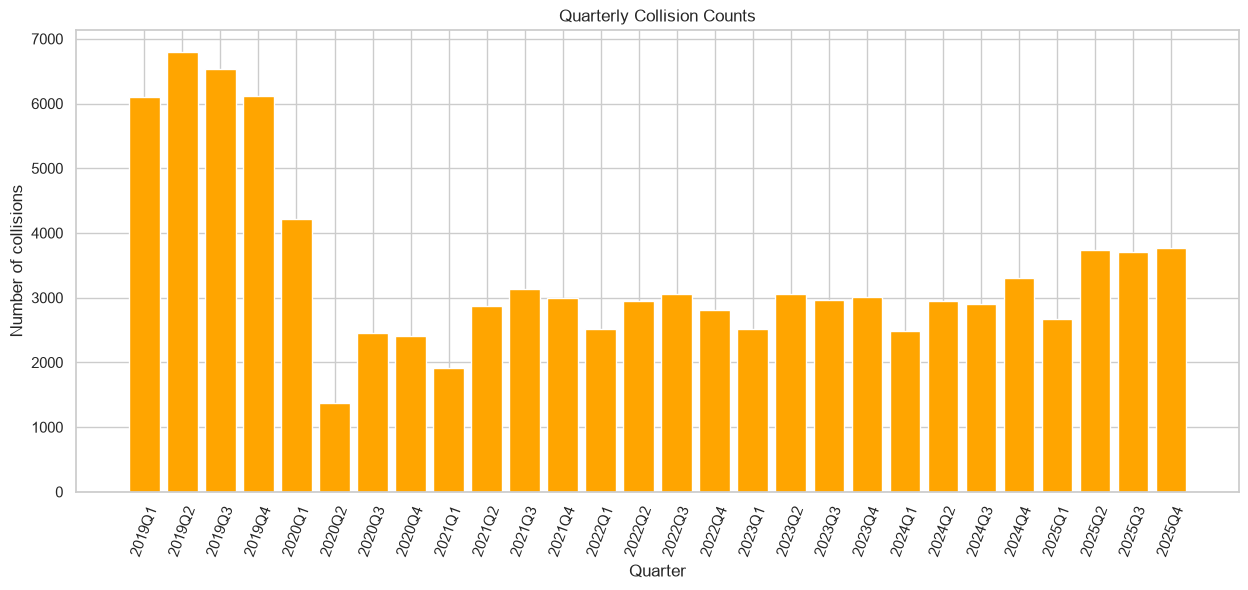

In [109]:
#plot collision counts 
sns.set_theme(style = 'whitegrid')



x = range(len(quarterly_count))
plt.figure(figsize = (15,6) )
plt.bar(x, quarterly_count.values, color = "orange")
plt.xticks(
    ticks=list(x)[::],
    labels=quarterly_count.index.astype(str)[::],
    rotation=70
)

plt.title("Quarterly Collision Counts")
plt.xlabel("Quarter")
plt.ylabel("Number of collisions")
plt.grid(True)
plt.show()

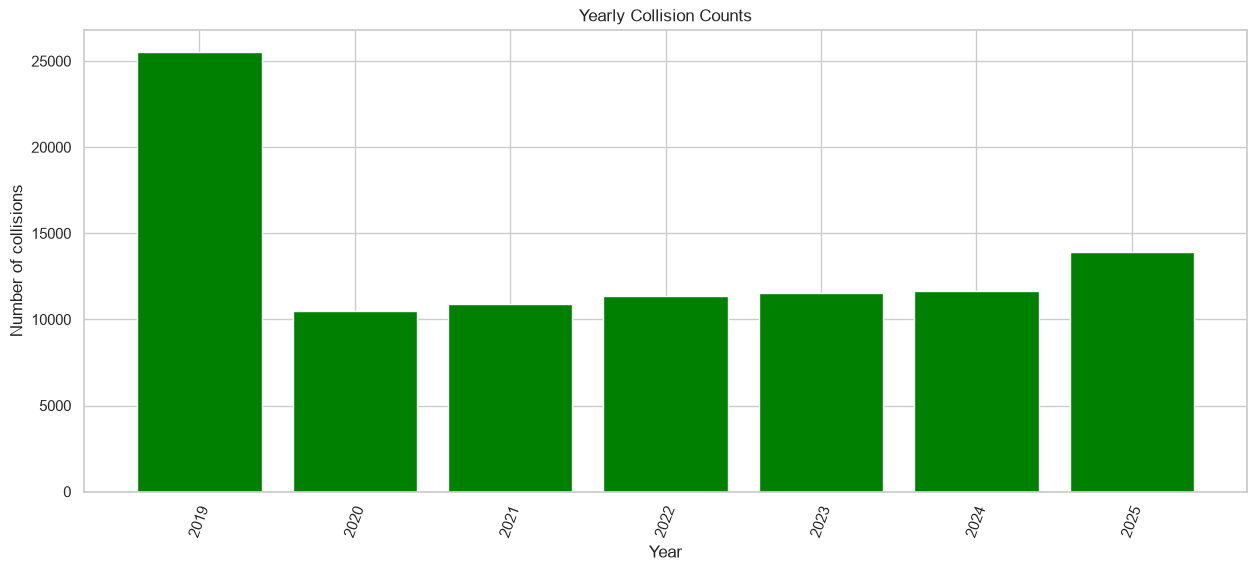

In [110]:
#plot collision counts 
sns.set_theme(style = 'whitegrid')



x = range(len(yearly_count))
plt.figure(figsize = (15,6) )
plt.bar(x, yearly_count.values, color = "green")
plt.xticks(
    ticks=list(x)[::],
    labels = yearly_count.index.astype(str)[::],
    rotation = 70
)

plt.title("Yearly Collision Counts")
plt.xlabel("Year")
plt.ylabel("Number of collisions")
plt.grid(True)
plt.show()

### 2.2 Spacial distribution
We need to verify that collisions are geographically concentrated in reasonable Manhattan locations.

/var/folders/h_/fcnc4bgx64j8j52221zpbjvr0000gn/T/ipykernel_9737/3464186301.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(df_eda["longitude"], df_eda['latitude'],alpha= 1, cmap='viridis')


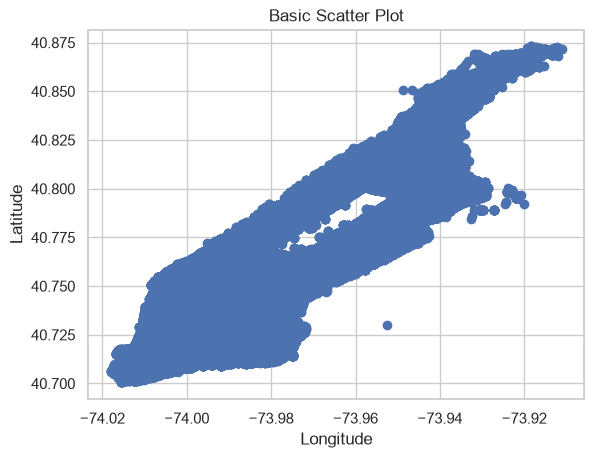

In [111]:
plt.scatter(df_eda["longitude"], df_eda['latitude'],alpha= 1, cmap='viridis')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Basic Scatter Plot")

# Display the plot
plt.show()

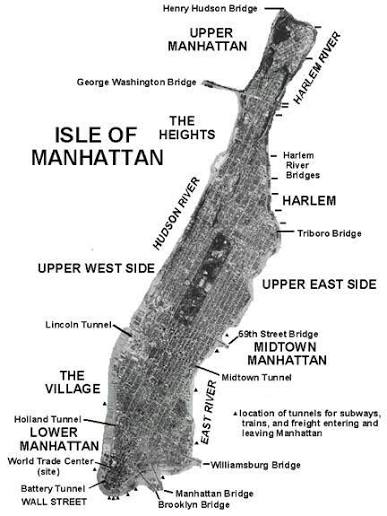

###  2.3 Examine quarterly collision counts

In [113]:
summary = quarterly_count.describe()
summary

count      28.000000
mean     3404.928571
std      1364.586464
min      1379.000000
25%      2629.750000
50%      2978.500000
75%      3714.500000
max      6799.000000
Name: count, dtype: float64

In [120]:
print(f"Average collisions per quarter: {quarterly_count.mean()}")
print(f"Minimum quarterly collision count: {quarterly_count.min()}")
print(f"Maximum quarterly collision count: {quarterly_count.max()}")
print(f"Number of quarters with zero collisions: {len(quarterly_count[quarterly_count == 0]) }")





Average collisions per quarter: 3404.9285714285716
Minimum quarterly collision count: 1379
Maximum quarterly collision count: 6799
Number of quarters with zero collisions: 0
